#AI-ML for prediction of half-life in food animal

# Installing the Necessary Libraries or Packages

In [ ]:
!pip install -q PubChemPy==1.0.4             # Install PubChemPy library for accessing PubChem data
!pip install -q rdkit-pypi==2022.09.5        # Install rdkit-pypi package, a version of the RDKit cheminformatics toolkit
!pip install -q scikit-optimize     # Install scikit-optimize library for optimization in machine learning

In [ ]:
import pandas as pd                            # Data manipulation and analysis library
import numpy as np                             # Numerical operations library
np.int = np.int32                              # To slove the error about AttributeError: module 'numpy' has no attribute 'int'  # Set default integer type to int32
np.float = np.float64                          # Set default float type to float64
import seaborn as sns                          # Statistical data visualization library
import pubchempy as pcp                        # PubChem API for accessing chemical information
from pubchempy import get_compounds, Compound  # Functions for working with PubChem data
from collections import Counter                # Container for counting hashable objects

# Molecular Descriptors Calculation
from rdkit import Chem                                 # Toolkit for cheminformatics
from rdkit.Chem import AllChem, MACCSkeys, Descriptors, DataStructs  # Molecular descriptors and fingerprint generation
from rdkit.DataStructs import ExplicitBitVect          # Data structures for working with molecular descriptors
from rdkit.ML.Descriptors import MoleculeDescriptors   # Calculation of molecular descriptors

# Modeling
from sklearn.model_selection import train_test_split, cross_val_predict, cross_val_score, GridSearchCV, RandomizedSearchCV, KFold   # Model selection and evaluation tools
from sklearn import metrics                           # Metrics for evaluating model performance
from sklearn.preprocessing import MinMaxScaler        # Feature scaling for RDKit descriptors
from pandas.core.common import random_state           # Setting random state for reproducibility
from sklearn.neighbors import KNeighborsRegressor     # K-Nearest Neighbors regression algorithm development
from sklearn.ensemble import RandomForestRegressor    # Random Forest regression algorithm development
from sklearn.svm import SVR                           # Support Vector Regression algorithm development
from sklearn.metrics import mean_squared_error, r2_score, make_scorer   # Metrics for evaluating regression model performance

# Visualization
import matplotlib.pyplot as plt   # Plotting library
# Setting matplotlib to display plots inline in Jupyter notebooks
%matplotlib inline

# import the Data Set

In [ ]:
from google.colab import files
upload = files.upload()

Saving HL6_dataset.csv to HL6_dataset.csv


In [ ]:
#Check dataset
df = pd.read_csv('HL6_dataset.csv')
df

,CitationNumber,Drug,Analyte,CAS,Species,LambdaZHl
0,9018309,3-Methylindole,3-Methylindole,83-34-1,Goats,17.900000
1,9016661,3-Methyl-methcathinone,3-Methyl-methcathinone,1246816-62-5,Swine,0.830000
2,9016661,3-Methyl-methcathinone,mephedrone,1189805-46-6,Swine,0.400000
3,9015043,Acetaminophen,Acetaminophen,103-90-2,Chickens,0.610000
4,9015043,Acetaminophen,Acetaminophen,103-90-2,Turkeys,0.670000
...,...,...,...,...,...,...
334,9016147,Voriconazole,Voriconazole,137234-62-9,Chickens,1.990000
335,9016385,Zearalenone,Zearalenone,17924-92-4,Chickens,0.530106
336,9017540,Zearalenone,Zearalenone,17924-92-4,Swine,15.000000
337,9018166,Zolmitriptan,Zolmitriptan,139264-17-8,Swine,4.000000


# Extracting SMILES Codes from PubChem Database

In [ ]:
'''
This script automates the retrieval of PubChem CID (Chemical Identifier) and corresponding SMILES
(Simplified Molecular Input Line Entry System) codes from the PubChem database.
The process involves connecting to PubChem, obtaining CID for given CAS
(Chemical Abstracts Service) Registry numbers, and resolving those CIDs to SMILES codes.

'''
# Function to convert CAS numbers to PubChem CIDs and update the DataFrame with PubChemCID column
def cas_to_cid (df):
  df['PubChemCID'] = None

  # Searching PubChem for CID
  for i, CAS in df['CAS'].items():
    try:
        # Searching PubChem for CID using CAS number
        results = get_compounds(CAS, 'name')
        if results:
            cid = results[0].cid
            df.at[i, 'PubChemCID'] = cid
        else:
            print(f"No results found for CAS number {CAS}")

    except Exception as e:
        pass # silent the error message; otherwise it will print a lot of error messages: server is busy

  # Check PubChemCID; If CID is None, run the "While loop" and request PubChem server again to get all Cid
  while df['PubChemCID'].isnull().sum() > 0:
    print (df['PubChemCID'].isnull().sum())
    for i, CAS in df[df['PubChemCID'].isnull()]['CAS'].items():
      try:
        # Searching PubChem for CID using CAS number
        results = get_compounds(CAS, 'name')
        if results:
            cid = results[0].cid
            df.at[i, 'PubChemCID'] = cid
        else:
            print(f"No results found for CAS number {CAS}")
      except Exception as e:
        pass

  return df

# Function for searching and extracting SMILES code with entering CID
def cid_to_smiles (data):
  data['SMILES'] = None

  for i, cid in data['PubChemCID'].items():
    try:
      compound = pcp.Compound.from_cid(cid)
      if compound:
        smiles = compound.canonical_smiles
        data.at[i, 'SMILES'] = smiles
      else:
        print(f'No results found for PubChemCID {cid}')

    except Exception as e: # a general exception handler
        pass # If an exception is caught, it will ignored, and the code will proceed without raising an error to avoid printing a lot of error messages related to a specific situation ("PUG-REST server is busy").

  # Check SMILES; If SMILES is None, run the "While loop" and request PubChem server again to get all SMILES
  while data['SMILES'].isnull().sum() > 0:
    print (data['SMILES'].isnull().sum())
    for i, cid in data[data['SMILES'].isnull()]['PubChemCID'].items():
     try:
       compound = pcp.Compound.from_cid(cid)
       if compound:
        smiles = compound.canonical_smiles
        data.at[i, 'SMILES'] = smiles
       else:
        print(f'No results found for PubChemCID {cid}')
     except Exception as e:
       pass

  return data

In [ ]:
# Define a function that transforms SMILES string into RDKIT descriptors
def cal_rdkit_descr(smiles):
    mols = [Chem.MolFromSmiles(i) for i in smiles]
    calc = MoleculeDescriptors.MolecularDescriptorCalculator([x[0] for x in Descriptors._descList])
    desc_names = calc.GetDescriptorNames()

    mol_descriptors = []
    for mol in mols:
        mol = Chem.AddHs(mol)
        descriptors = calc.CalcDescriptors(mol)
        mol_descriptors.append(descriptors)

    return pd.DataFrame(mol_descriptors, index=smiles, columns=["rdkit_" + str(i) for i in desc_names])

In [ ]:
#Transform the feature to similes
df_with_cids = cas_to_cid(df) # CAS convert to pubChem CID
df_with_smiles = cid_to_smiles(df_with_cids) # pubChem CID  convert to smiles

14
1
48
6


In [ ]:
#Define ouput prediction(y)
y = df['LambdaZHl']  # Half-life

In [ ]:
# pearson's correlation feature selection for numeric input and numeric output
from sklearn.datasets import make_regression
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_regression

# Calculating RDKit descriptors
rdkit_descrs = cal_rdkit_descr(df_with_smiles['SMILES']).drop(['rdkit_BCUT2D_MWHI', 'rdkit_BCUT2D_MWLOW', 'rdkit_BCUT2D_CHGHI', 'rdkit_BCUT2D_CHGLO', 'rdkit_BCUT2D_LOGPHI', 'rdkit_BCUT2D_LOGPLOW', 'rdkit_BCUT2D_MRHI', 'rdkit_BCUT2D_MRLOW'],axis=1)

#Selected
fs = SelectKBest(score_func=f_regression, k=15)
# apply feature selection
X_selected_rdkit = pd.DataFrame(fs.fit_transform(rdkit_descrs,y))
cols = fs.get_feature_names_out()
X_selected_rdkit.columns = cols
print(X_selected_rdkit)

     rdkit_MinEStateIndex  rdkit_MinAbsEStateIndex  rdkit_PEOE_VSA6  \
0               -2.722364                 0.286111        18.127256   
1               -3.841423                 0.790227        23.690708   
2               -3.815249                 0.778650        29.733126   
3               -3.157138                 0.206873         0.000000   
4               -3.157138                 0.206873         0.000000   
..                    ...                      ...              ...   
334             -4.393125                 0.281064        12.894311   
335             -4.757754                 1.273738        12.104143   
336             -4.757754                 1.273738        12.104143   
337             -4.098336                 0.055465         6.042419   
338             -3.463490                 0.220508         0.000000   

     rdkit_SMR_VSA5  rdkit_SlogP_VSA5  rdkit_EState_VSA10  rdkit_EState_VSA4  \
0          6.851892         16.529520            0.000000          

In [ ]:
# Applying feature scaling for RDKit descriptors
scaler = MinMaxScaler()
X_selected_rdkit_descrs = X_selected_rdkit
X_selected_rdkit_descrs_scal = scaler.fit_transform(X_selected_rdkit_descrs)
X_selected_rdkit_descrs_scal = pd.DataFrame(X_selected_rdkit_descrs_scal, columns = X_selected_rdkit_descrs.columns.values.tolist())
X_selected_rdkit_descrs_scal

,rdkit_MinEStateIndex,rdkit_MinAbsEStateIndex,rdkit_PEOE_VSA6,rdkit_SMR_VSA5,rdkit_SlogP_VSA5,rdkit_EState_VSA10,rdkit_EState_VSA4,rdkit_EState_VSA9,rdkit_VSA_EState1,rdkit_VSA_EState7,rdkit_MolLogP,rdkit_fr_alkyl_halide,rdkit_fr_allylic_oxid,rdkit_fr_ester,rdkit_fr_halogen
0,0.742433,0.078385,0.150000,0.024837,0.037505,0.000000,0.0,0.032022,0.034303,0.996594,0.653915,0.0,0.000000,0.000000,0.0
1,0.608151,0.216495,0.196037,0.071487,0.123858,0.052185,0.0,0.079699,0.080580,1.000000,0.616353,0.0,0.000000,0.000000,0.0
2,0.611291,0.213324,0.246037,0.071487,0.123858,0.052185,0.0,0.079699,0.080433,1.000000,0.616353,0.0,0.000000,0.000000,0.0
3,0.690262,0.056676,0.000000,0.024837,0.037225,0.052185,0.0,0.032373,0.031139,1.000000,0.592696,0.0,0.000000,0.000000,0.0
4,0.690262,0.056676,0.000000,0.024837,0.037225,0.052185,0.0,0.032373,0.031139,1.000000,0.592696,0.0,0.000000,0.000000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
334,0.541949,0.077002,0.106698,0.090054,0.123380,0.047786,0.0,0.071865,0.127826,0.972603,0.637632,0.0,0.000000,0.000000,0.3
335,0.498195,0.348961,0.100160,0.185479,0.281605,0.104370,0.0,0.135784,0.152222,0.831341,0.713914,0.0,0.111111,0.333333,0.0
336,0.498195,0.348961,0.100160,0.185479,0.281605,0.104370,0.0,0.135784,0.152222,0.831341,0.713914,0.0,0.111111,0.333333,0.0
337,0.577322,0.015196,0.050000,0.068015,0.107587,0.052185,0.0,0.127614,0.144854,0.942641,0.623819,0.0,0.000000,0.000000,0.0


In [ ]:
# Convert the "Species" to binary values with one-hot encoding
species_descr = pd.get_dummies(df['Species'])
species_descr = species_descr.astype(int)
species_descr.head()

,Cattle,Chickens,Goats,Sheep,Swine,Turkeys
0,0,0,1,0,0,0
1,0,0,0,0,1,0
2,0,0,0,0,1,0
3,0,1,0,0,0,0
4,0,0,0,0,0,1


In [ ]:
#Combine animal species and molecular descriptors
X_rdkit = pd.concat([species_descr, X_selected_rdkit_descrs_scal.reset_index(drop=True)], axis = 1)
print(X_rdkit.shape, y.shape)

(339, 21) (339,)


# Build Machine Learning Modeling Pipeline

In [ ]:
# install package
import sklearn                                                # Scikit-learn, a machine learning library
from sklearn.neighbors import KNeighborsRegressor             # K-Nearest Neighbors (KNN) regression algorithm
from sklearn.ensemble import RandomForestRegressor            # Random Forest (RF) regression algorithm
from sklearn.svm import SVR                                   # Support Vector Regression (SVR) algorithm
from sklearn.model_selection import train_test_split          # Function for splitting data into training and testing sets
from sklearn.preprocessing import MinMaxScaler                # Feature scaling
from sklearn.model_selection import KFold                     # K-Fold cross-validation
from sklearn.metrics import r2_score                          # R-squared score metric for regression
from sklearn.metrics import mean_squared_error as mse         # Mean Squared Error metric
import warnings                                               # Warning control
warnings.filterwarnings("ignore")                             # Ignore warning messages
from skopt import BayesSearchCV                               # Bayesian optimization for hyperparameter tuning
from skopt.callbacks import DeadlineStopper, DeltaYStopper    # Callbacks for stopping optimization
from skopt.space import Real, Categorical, Integer            # Search space for hyperparameter tuning
from sklearn.model_selection import RepeatedStratifiedKFold   # Repeated Stratified K-Fold cross-validation

In [ ]:
# KNN parameters distribution for hyperparameter tuning
knn_parm_search = {
    'n_neighbors': [1, 10, 50],         # Number of neighbors to consider
    'weights': ['uniform', 'distance']  # Weighting scheme for neighbors: 'uniform' or 'distance'
}

# RandomForest parameter distribution for hyperparameter tuning
rf_parm_search = {
     'bootstrap': [True, False],        # Whether to bootstrap samples
     'max_depth': [50, 150, 200],       # Maximum depth of the trees
     'max_features': ['sqrt'],  # Maximum number of features to consider for splitting
     'min_samples_leaf': [5, 10, 15],   # Minimum number of samples required to be a leaf node
     'min_samples_split': [5, 10, 150], # Minimum number of samples required to split an internal node
     'max_leaf_nodes': [50, 150, 200],  # Maximum number of leaf nodes
     'n_estimators': [50, 150, 200],    # Number of trees in the forest
}

# SVR parameters distribution for hyperparameter tuning
svr_parm_search = {
     'C': [1, 50, 100],                 # Regularization parameter
     "kernel": ['linear', 'poly', 'rbf', 'sigmoid'],  # Kernel type for the algorithm
     'gamma': ['scale', 'auto'],        # Kernel coefficient
}

In [ ]:
models = {
    'KNN': (KNeighborsRegressor(), knn_parm_search),
    'RF': (RandomForestRegressor(), rf_parm_search),
    'SVR': (SVR(), svr_parm_search)
}

In [ ]:
# Hyperparameter tuning for three algorithms: KNN, RF, and SVR
def tuning_hyper(X, y, model_name):
    model, parm_search = models[model_name]

    X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=2)

    cv = KFold(n_splits=5, shuffle=True, random_state=2)
    r2_kfolds_mean = []
    r2_kfolds_sd = []
    rmse_mean = []
    rmse_sd  = []

    bs = BayesSearchCV(
      estimator = model,
      search_spaces = parm_search,
      cv = 5,
      n_iter = 80,
      n_jobs = -1,
      scoring = "r2",
      return_train_score=True,
      random_state = 2
   )

    bs.fit(X_train, y_train)

    best_model = bs.best_estimator_
    best_params = bs.best_params_
    y_hat_train = best_model.predict(X_train)
    y_hat_test = best_model.predict(X_test)
    y_obs = y.tolist()

    r2_kfolds = cross_val_score(best_model, X_train, y_train, cv = 5, n_jobs=-1, scoring='r2')
    rmse_kfolds = cross_val_score(best_model, X_train, y_train, cv = 5, n_jobs=-1, scoring='neg_root_mean_squared_error')
    r2_train = r2_score(y_train, y_hat_train)
    r2_test = r2_score(y_test, y_hat_test)
    rmse_train = mean_squared_error(y_train, y_hat_train, squared=False)
    rmse_test = mean_squared_error(y_test, y_hat_test, squared=False)

    results = {'cv_r2_mean': [], 'cv_r2_sd':[],
        'cv_rmse_mean': [], 'cv_rmse_sd': [],
        'r2_train': [], 'r2_test': [], 'rmse_train':[], 'rmse_test':[]}

    results['cv_r2_mean'].append(r2_kfolds.mean())
    results['cv_r2_sd'].append(r2_kfolds.std())
    results['cv_rmse_mean'].append(-1*rmse_kfolds.mean())
    results['cv_rmse_sd'].append(rmse_kfolds.std())
    results['r2_train'].append(r2_train)
    results['r2_test'].append(r2_test)
    results['rmse_train'].append(rmse_train)
    results['rmse_test'].append(rmse_test)

    return best_model, best_params, results, X_train, X_test, y_train, y_test, y_hat_train, y_hat_test

In [ ]:
feature_types = ['X_rdkit']  # Descriptors

In [ ]:
# Print the R2 and RMSE results for hyperparameter tuning simultaneously for three algorithms: KNN, RF, and SVR with five types of descriptors
for feature_type, X in zip(feature_types, [X_rdkit]):
    print(f"========== Feature Type: {feature_type} ==========")

    for model_name, (model, _) in models.items():
        print(f"Model: {model_name}")
        best_model, best_params, results, X_train, X_test, y_train, y_test, y_hat_train, y_hat_test = tuning_hyper(X=X, y=y, model_name=model_name)
        print("Best Params:", best_params)
        print("Results:", results)
        print("\n")

========== Feature Type: X_rdkit ==========
Model: KNN
Best Params: OrderedDict([('n_neighbors', 50), ('weights', 'distance')])
Results: {'cv_r2_mean': [0.015255574697906416], 'cv_r2_sd': [0.11180374234893316], 'cv_rmse_mean': [41.0124490262459], 'cv_rmse_sd': [19.661574129758144], 'r2_train': [0.9999509143735703], 'r2_test': [0.09576285575545129], 'rmse_train': [0.32530873462908616], 'rmse_test': [24.601818524234552]}


Model: RF
Best Params: OrderedDict([('bootstrap', True), ('max_depth', 150), ('max_features', 'sqrt'), ('max_leaf_nodes', 200), ('min_samples_leaf', 10), ('min_samples_split', 5), ('n_estimators', 50)])
Results: {'cv_r2_mean': [-0.02517083552886168], 'cv_r2_sd': [0.29635245090478624], 'cv_rmse_mean': [39.4672140543477], 'cv_rmse_sd': [17.095299588021152], 'r2_train': [0.23506673456725746], 'r2_test': [0.1953012919582915], 'rmse_train': [40.609751263292786], 'rmse_test': [23.208265874849914]}


Model: SVR
Best Params: OrderedDict([('C', 100), ('gamma', 'scale'), ('kerne

##Applicability Domain for KNN, RF, and SVR Models

========== Feature Type: RDKit ==========
Model: KNN


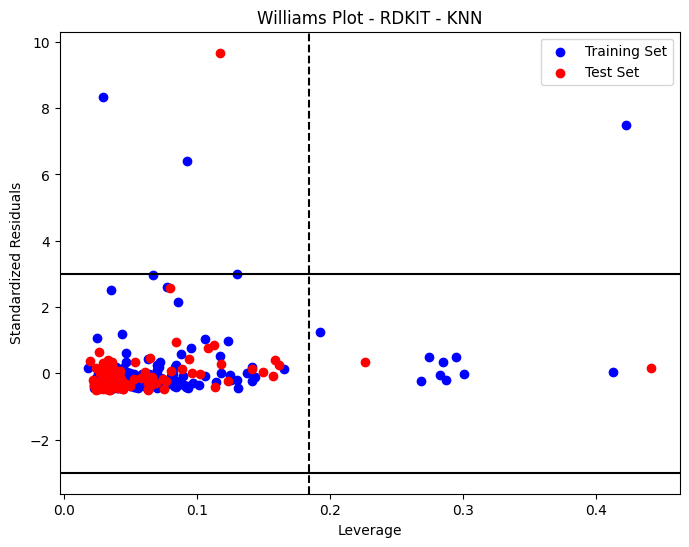



Model: RF


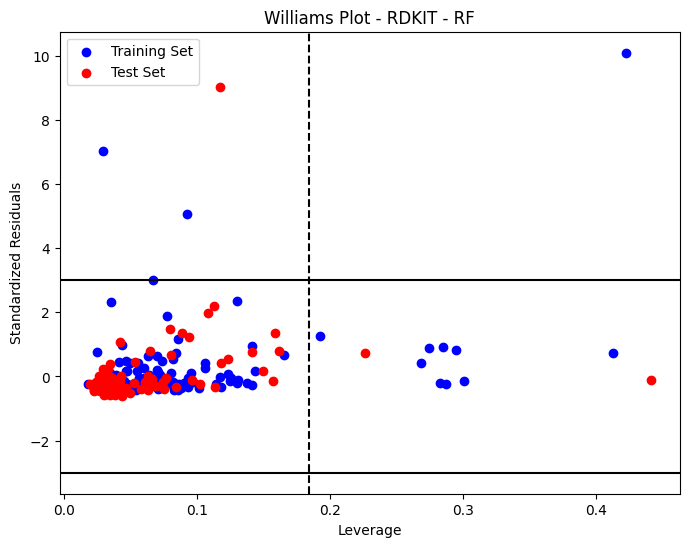



Model: SVR


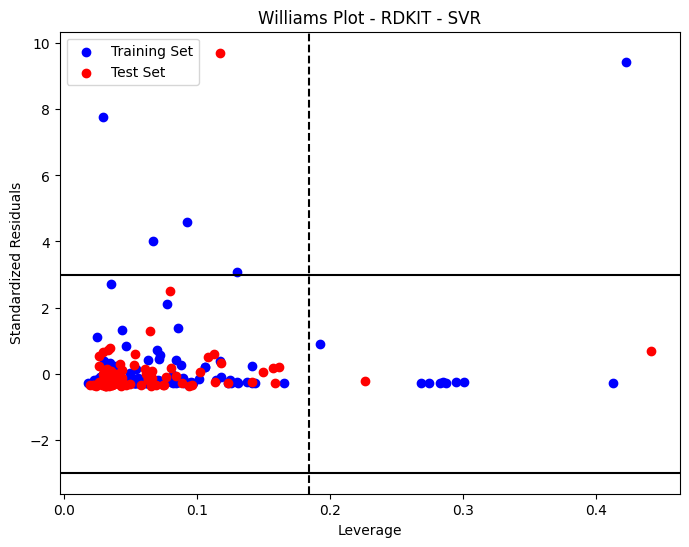

In [ ]:
# Define the applicability domain function
def hat_matrix(X, random_seed=None):
    np.random.seed(random_seed)       # set random state for reproducibility

    xtx = np.dot(X.T, X)
    np.fill_diagonal(xtx, np.diagonal(xtx) + np.random.uniform(0.001, 0.002, size=len(xtx)))
    ixtx = np.linalg.pinv(xtx)
    return np.dot(np.dot(X, ixtx), X.T)

def eval_ad(X_train, X_test, y_train, y_test, model):

    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    H_train = hat_matrix(np.vstack((X_train, X_test)), random_seed=2)     # set random state for reproducibility

    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    residual_train = np.abs(y_train - y_pred_train)
    residual_test = np.abs(y_test - y_pred_test)
    s_residual_train = (residual_train - np.mean(residual_train)) / np.std(residual_train)
    s_residual_test = (residual_test - np.mean(residual_test)) / np.std(residual_test)

    leverage_train = np.diag(H_train)[:X_train.shape[0]]
    leverage_test = np.diag(H_train)[X_train.shape[0]:]

    p = X_train.shape[1] + 1                # features
    n = X_train.shape[0] + X_test.shape[0]  # total compounds
    h_star = (3 * p) / n

    AD_train = 100 * np.sum((leverage_train < h_star) & (np.abs(s_residual_train) < 3)) / len(leverage_train)
    AD_test = 100 * np.sum((leverage_test < h_star) & (np.abs(s_residual_test) < 3)) / len(leverage_test)

    return AD_train, AD_test, s_residual_train, s_residual_test, leverage_train, leverage_test

feature_types = ['RDKit']

for feature_type, X in zip(feature_types, [X_rdkit]):
    print(f"========== Feature Type: {feature_type} ==========")

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=2)

    for model_name, (model, _) in models.items():
        print(f"Model: {model_name}")
        best_model, best_params, results, X_train, X_test, y_train, y_test, y_hat_train, y_hat_test = tuning_hyper(X=X, y=y, model_name=model_name)
        AD_train, AD_test, s_residual_train, s_residual_test, leverage_train, leverage_test = eval_ad(X_train, X_test, y_train, y_test, best_model)

        # Find chemicals exceeding AD area
        train_exceed_AD = (leverage_train > np.mean(leverage_train) + 2 * np.std(leverage_train)) | \
                          (np.abs(s_residual_train) > 3)

        # Create Williams plot for three algorithms: KNN, RF, and SVR
        plt.figure(figsize=(8, 6))
        plt.scatter(leverage_train, s_residual_train, c='blue', label='Training Set')
        plt.scatter(leverage_test, s_residual_test, c='red', label='Test Set')
        plt.axhline(y=np.mean(s_residual_train) + 3 * np.std(s_residual_train), color='black', linestyle='-')
        plt.axhline(y=np.mean(s_residual_train) - 3 * np.std(s_residual_train), color='black', linestyle='-')
        plt.axvline(x=np.mean(leverage_train) + 2 * np.std(leverage_train), color='black', linestyle='--')
        plt.xlabel('Leverage')
        plt.ylabel('Standardized Residuals')
        plt.title(f'Williams Plot - {feature_type.upper()} - {model_name}')
        plt.legend()
        plt.show()

        print("\n")

    print("=============================================\n")

## Example: Linear regression analysis for SVR model

In [ ]:
'''
To comply with the correlation code rules, please avoid using duplicate species columns.
'''
X_rdkit_NS = pd.concat([X_selected_rdkit_descrs_scal.reset_index(drop=True)], axis = 1)

In [ ]:
# Please replace 'model_name' here with either 'KNN', 'RF', or 'SVR'.
# Here, the correlation plot will be generated for only one algorithm with one descriptor or fingerprint at a time.
print("========== SVR ==========")
model_name = 'SVR'
model, _ = models[model_name]
best_model, best_params, results, X_train, X_test, y_train, y_test, y_hat_train, y_hat_test = tuning_hyper(X=X_rdkit, y=y, model_name=model_name)
print("Best Params:", best_params)
print("Results:", results)
print("\n")

========== SVR ==========
Best Params: OrderedDict([('C', 100), ('gamma', 'scale'), ('kernel', 'rbf')])
Results: {'cv_r2_mean': [0.12417664910332626], 'cv_r2_sd': [0.0870718187211883], 'cv_rmse_mean': [39.44875528102652], 'cv_rmse_sd': [19.724025102853712], 'r2_train': [0.2995629174060075], 'r2_test': [0.21982319188567945], 'rmse_train': [38.86002902911266], 'rmse_test': [22.85191274618007]}




In [ ]:
# This code adds columns of the observed and corresponding predicted response variables for half-lives of both training and test sets to one descriptor or fingerprint.
X_rdkit.loc[X_test.index,'y_hat_test'] = y_hat_test
X_rdkit.loc[X_train.index,'y_hat_train'] = y_hat_train
X_rdkit.loc[y_test.index,'y_test'] = y_test
X_rdkit.loc[y_train.index,'y_train'] = y_train

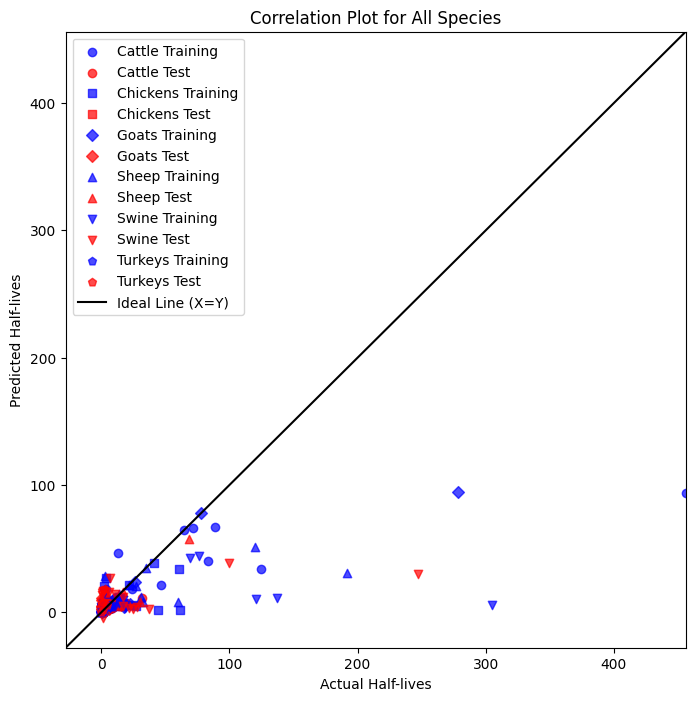

In [ ]:
#Plot the correlation for a single algorithm with RDikt or fingerprint in both the training and test sets on a single plot

animal_list = ['Cattle', 'Chickens', 'Goats', 'Sheep', 'Swine', 'Turkeys']

# Initialize lists to store data for all species
all_y_train = []
all_y_train_preds = []
all_y_test = []
all_y_test_preds = []

# Define plotting markers for each species
markers = ['o', 's', 'D', '^', 'v', 'p']

# Create a scatter plot with a line of r=1 for all species
plt.figure(figsize=(8, 8))  # Make the plot square

# Loop through each species and collect data
for idx, animal in enumerate(animal_list):
    # Filter the data for the current species
    species_data = X_rdkit[X_rdkit[animal] == 1]

    # Check if there are any data points left for plotting
    if not species_data.empty:

        # Collect data for training and test sets
        y_train = species_data['y_train']
        y_train_preds = species_data['y_hat_train']
        y_test = species_data['y_test']
        y_test_preds = species_data['y_hat_test']

        # Store data for all species
        all_y_train.extend(y_train)
        all_y_train_preds.extend(y_train_preds)
        all_y_test.extend(y_test)
        all_y_test_preds.extend(y_test_preds)

        # Plot training set data points for the current species in a darker shade
        plt.scatter(y_train, y_train_preds, color='blue', marker=markers[idx], label=f'{animal} Training', alpha=0.7)

        # Plot test set data points for the current species in a lighter shade
        plt.scatter(y_test, y_test_preds, color='red', marker=markers[idx], label=f'{animal} Test', alpha=0.7)

# Ensure no NaN or Inf values in the data
all_values = all_y_train + all_y_train_preds + all_y_test + all_y_test_preds
all_values = np.array(all_values)

# Check for NaN or Inf values
if np.any(np.isnan(all_values)) or np.any(np.isinf(all_values)):
    all_values = all_values[~np.isnan(all_values)]
    all_values = all_values[~np.isinf(all_values)]

# Calculate min_val and max_val based on valid data
data_range = max(all_values) - min(all_values)
min_val = min(all_values) - 0.05 * data_range if data_range != 0 else 0  # Avoid division by zero
max_val = max(all_values)

# Plot the ideal line (X=Y)
plt.plot([min_val, max_val], [min_val, max_val], linestyle='-', color='black', label="Ideal Line (X=Y)")

plt.title('Correlation Plot for All Species')
plt.xlabel('Actual Half-lives')
plt.ylabel('Predicted Half-lives')

# Set the limits for both X and Y axes
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)

plt.legend()
plt.show()

# Deep Neural Network Model with Keras

In [ ]:
# Install python pacakges
!pip install -q --upgrade typing-extensions>=4.6.0 --no-warn-script-location
!pip install -q scikit-optimize --no-warn-script-location
!pip install -q scikeras[tensorflow] --no-warn-script-location
!pip install -q keras-tuner --upgrade --no-warn-script-location

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.1/129.1 kB 2.3 MB/s eta 0:00:00


In [ ]:
# Import basic packages for data manipulation, visualization, and machine learning
import numpy as np                                       # Numerical operations
import seaborn as sns                                    # Statistical data visualization
import pandas as pd                                      # Data manipulation and analysis
import tensorflow as tf                                  # Open-source machine learning framework
import os                                                # Operating system functionality
import scikeras                                          # Keras-based interface for scikit-learn
from tensorflow import keras                             # Keras API for building and training neural networks
import matplotlib.pyplot as plt                          # Plotting library
from mpl_toolkits.axes_grid1 import make_axes_locatable  # Toolkit for creating plots with colorbars
import matplotlib.colors as colors                       # Color mapping and normalization
import matplotlib as mpl                                 # Matplotlib library for plotting
import keras_tuner                                       # Hyperparameter tuning library
from numpy.random import seed                            # Seed for reproducibility
import tensorflow                                        # Importing TensorFlow module

# Import Keras-related packages for building neural networks
from tensorflow import keras                             # Keras API for building and training neural networks
from keras.models import Sequential                      # Linear stack of layers for building models
from keras.layers import Dense                           # Fully connected layer
from keras.layers import Dropout                         # Dropout regularization for reducing overfitting
from keras import regularizers                           # Regularization techniques for neural networks
from tensorflow.keras.optimizers import Adam, SGD        # Optimization algorithms
from tensorflow.keras.optimizers.schedules import ExponentialDecay  # Learning rate schedule
from keras.models import load_model                      # Load pre-trained models
from keras.callbacks import EarlyStopping                # Early stopping during model training
from keras_tuner import BayesianOptimization             # Bayesian optimization for hyperparameter tuning
from tensorflow import keras                             # Keras API for building and training neural networks
from tensorflow.keras import layers                      # Keras layers for building models
from keras_tuner import Objective                        # Objective functions for hyperparameter tuning
from tensorflow.keras.optimizers import Adam             # Adam optimizer
from sklearn.metrics import mean_squared_error as mse    # Mean Squared Error metric
from sklearn.model_selection import KFold                # KFold from scikit-learn for cross-validation
from keras.callbacks import EarlyStopping                # Earlystop avoid overfitting

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow import keras

def build_model(hp):
    model = Sequential()

    # Input layer
    model.add(Input(shape=(X_rdkit.shape[1],)))  # Define input shape using Input layer

    model.add(Dense(
        units=hp.Int('dense-bot', min_value=21, max_value=1024, step=32, default=21),
        activation=hp.Choice('dense_activation', values=['relu', 'tanh', 'sigmoid'], default='relu')
    ))

    # Tune the number of units in each dense layer
    for i in range(hp.Int('num_dense_layers', 1, 3)):
        model.add(Dense(
            units=hp.Int('dense_' + str(i), min_value=21, max_value=512, step=32),
            activation=hp.Choice('act_l' + str(i), values=['relu', 'tanh', 'sigmoid'])
        ))
        # Tune the dropout rate in each dense layer
        model.add(Dropout(hp.Choice('dropout_' + str(i), values=[0.0, 0.1, 0.2, 0.3, 0.5])))

    # Add output layer
    model.add(Dense(1, activation='linear'))

    # Select optimizer
    hp_optimizer = hp.Choice('Optimizer', values=['Adam', 'SGD'])

    # Set learning rate based on optimizer choice
    hp_learning_rate = hp.Choice('learning_rate', values=[1e-1, 1e-2, 1e-3, 1e-4, 1e-5])

    # Compile model with selected optimizer and learning rate
    if hp_optimizer == 'Adam':
        optimizer = keras.optimizers.Adam(learning_rate=hp_learning_rate)
    else:  # SGD
        optimizer = keras.optimizers.SGD(learning_rate=hp_learning_rate, nesterov=True, momentum=0.9)

    model.compile(optimizer=optimizer, loss='mse', metrics=['mse'])

    return model


In [ ]:
# Check if the model code works correctly
build_model(keras_tuner.HyperParameters())

<Sequential name=sequential_1, built=True>

In [ ]:
# seed the random number generator to reproduce the same results
seed(1)
tensorflow.random.set_seed(2)

In [ ]:
X_rdkit = pd.concat([species_descr, X_selected_rdkit_descrs_scal.reset_index(drop=True)], axis = 1)
y = df['LambdaZHl']  # Half-life
X_train, X_test, y_train, y_test = train_test_split(X_rdkit, y, test_size=0.33, random_state=2)

In [ ]:
tuner_bo = BayesianOptimization(
            hypermodel = build_model, # The defined keras-tuner model
            objective = 'val_mse',    # The name of the objective to optimize; 'val_mse' is validation 'mean squared error'
            max_trials = 10,          # the number of combinations of hyperparameters to be tried/executed
            overwrite = True,
            executions_per_trial=3)   # the number of times a single combination has to be executed

tuner_bo.search(X_train, y_train,
        validation_data=(X_test, y_test),
        batch_size =64,
        epochs = 500, verbose = 0)

In [ ]:
# Get the top 2 models
best_params_all=tuner_bo.get_best_hyperparameters()
best_params_all[0].values

{'dense-bot': 949,
 'dense_activation': 'sigmoid',
 'num_dense_layers': 3,
 'dense_0': 117,
 'act_l0': 'tanh',
 'dropout_0': 0.3,
 'Optimizer': 'Adam',
 'learning_rate': 0.001,
 'dense_1': 309,
 'act_l1': 'tanh',
 'dropout_1': 0.1,
 'dense_2': 245,
 'act_l2': 'relu',
 'dropout_2': 0.3}

In [ ]:
# Get the best model from Bayesian Optimization tuning
best_model_all= tuner_bo.get_best_models()[0]
# Display the summary of the best model
best_model_all.summary()

/usr/local/lib/python3.10/dist-packages/keras/src/saving/saving_lib.py:576: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 949)                 │          20,878 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 117)                 │         111,150 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 117)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 309)                 │          36,462 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 309)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 245)                 │          75,950 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 245)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 1)                   │             246 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 244,686 (955.80 KB)

 Trainable params: 244,686 (955.80 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# save the model and architecture to a single file in GoogleDrive
best_model_all.save("best_model_rdikt.keras")
print("Saved model to disk")

Saved model to disk


In [ ]:
#Load model and eveluate model
best_model_v2 = load_model('best_model_rdikt.keras')
y_test_preds_v2 = best_model_v2.predict(X_test)
y_train_preds_v2 = best_model_v2.predict(X_train)

# Print R2 and RMSE for both training and test sets
print("\nTest R2 Score: %.2f" %r2_score(y_test, y_test_preds_v2))
print("Train R2 Score: %.2f" %r2_score(y_train, y_train_preds_v2), '\n')

print("Test RMSE: %.2f" %mse(y_test, y_test_preds_v2, squared=False))
print("Train RMSE: %.2f" %mse(y_train, y_train_preds_v2, squared=False))

/usr/local/lib/python3.10/dist-packages/keras/src/saving/saving_lib.py:576: UserWarning: Skipping variable loading for optimizer 'SGD', because it has 8 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 

Test R2 Score: 0.46
Train R2 Score: 0.70 

Test RMSE: 19.02
Train RMSE: 25.52


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [ ]:
# Estimating the 5-CV R2 and RMSE for the training sets

dnn_best_model = best_model_v2

kfold = KFold(n_splits=5, shuffle=True, random_state=42)
cvr2scores = []
cvrmsescores = []

for train_ix, test_ix in kfold.split(X_train):
  # split data
  X_trian_n, X_test_n = X_train.values[train_ix], X_train.values[test_ix]
  y_trian_n, y_test_n = y_train.values[train_ix], y_train.values[test_ix]
  # create model

  dnn_best_model.fit(X_trian_n,y_trian_n, epochs=500, batch_size=64, verbose=0)
  test_pred = dnn_best_model.predict(X_test_n)
  r2score = r2_score(y_test_n, test_pred)
  rmse   = mse(y_test_n, test_pred,squared=False)

  cvr2scores.append(r2score)
  cvrmsescores.append(rmse)

print("The 5-cv r2 Score was: %.2f (+/-) %.2f" % (np.mean(cvr2scores), np.std(cvr2scores)))
print("The 5-cv rmse Score was: %.2f (+/-) %.2f" % (np.mean(cvrmsescores), np.std(cvrmsescores)))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
The 5-cv r2 Score was: 0.69 (+/-) 0.24
The 5-cv rmse Score was: 18.81 (+/-) 12.17


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


## Applicability Domain for DNN Model

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


/usr/local/lib/python3.10/dist-packages/keras/src/saving/saving_lib.py:576: UserWarning: Skipping variable loading for optimizer 'SGD', because it has 8 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


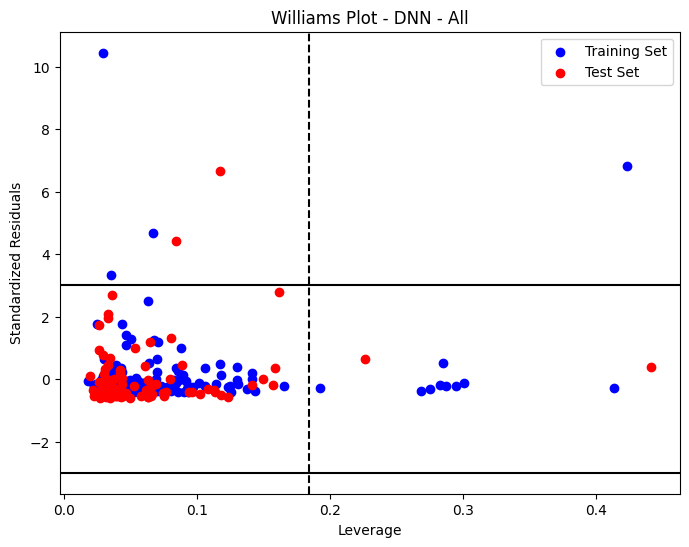

In [ ]:
# Set random seed for reproducibility
np.random.seed(42)

# Load the best DNN model from the BayesianOptimization search
best_model_all = load_model("best_model_rdikt.keras")

def hat_matrix(X):
    xtx = np.dot(X.T, X)
    np.fill_diagonal(xtx, np.diagonal(xtx) + np.random.uniform(0.001, 0.002, size=len(xtx)))
    ixtx = np.linalg.pinv(xtx)
    return np.dot(np.dot(X, ixtx), X.T)

# Define the applicability domain function for DNN
def eval_ad_dnn(X_train, X_test, y_train, y_test, model):

    # Get predictions from the DNN model
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    # Reshape y_train and y_pred_train to 1-dimensional arrays
    y_train = y_train.to_numpy().reshape(-1)
    y_pred_train = y_pred_train.reshape(-1)
    y_pred_train = y_pred_train.reshape(-1)
    y_pred_test = y_pred_test.reshape(-1)

    residual_train = np.abs(y_train - y_pred_train)
    residual_test = np.abs(y_test - y_pred_test)
    s_residual_train = (residual_train - np.mean(residual_train)) / np.std(residual_train)
    s_residual_test = (residual_test - np.mean(residual_test)) / np.std(residual_test)

    H_train = hat_matrix(np.vstack((X_train, X_test)))

    leverage_train = np.diag(H_train)[:X_train.shape[0]]
    leverage_test = np.diag(H_train)[X_train.shape[0]:]

    p = X_train.shape[1] + 1  # features
    n = X_train.shape[0] + X_test.shape[0]  # total compounds
    h_star = (3 * p) / n

    AD_train = 100 * np.sum((leverage_train < h_star) & (np.abs(s_residual_train) < 3)) / len(leverage_train)
    AD_test = 100 * np.sum((leverage_test < h_star) & (np.abs(s_residual_test) < 3)) / len(leverage_test)

    return AD_train, AD_test, s_residual_train, s_residual_test, leverage_train, leverage_test

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X_rdkit, y, test_size=0.33, random_state=2)

# Evaluate applicability domain for the best DNN model
AD_train, AD_test, s_residual_train, s_residual_test, leverage_train, leverage_test = eval_ad_dnn(X_train, X_test, y_train, y_test, best_model_all)

# Find chemicals exceeding AD area
train_exceed_AD = (leverage_train > np.mean(leverage_train) + 2 * np.std(leverage_train)) | \
                  (np.abs(s_residual_train) > 3)

test_exceed_AD = (leverage_test > np.mean(leverage_test) + 2 * np.std(leverage_test)) | \
                 (np.abs(s_residual_test) > 3)

# Create Williams plot for DNN model
plt.figure(figsize=(8, 6))
plt.scatter(leverage_train, s_residual_train, c='blue', label='Training Set')
plt.scatter(leverage_test, s_residual_test, c='red', label='Test Set')
plt.axhline(y=np.mean(s_residual_train) + 3 * np.std(s_residual_train), color='black', linestyle='-')
plt.axhline(y=np.mean(s_residual_train) - 3 * np.std(s_residual_train), color='black', linestyle='-')
plt.axvline(x=np.mean(leverage_train) + 2 * np.std(leverage_train), color='black', linestyle='--')
plt.xlabel('Leverage')
plt.ylabel('Standardized Residuals')
plt.title('Williams Plot - DNN - All')
plt.legend()
plt.show()

# Adjust indices for the original training set
train_exceed_indices_original = np.where(train_exceed_AD)[0]
train_exceed_indices_original[train_exceed_indices_original < X_train.shape[0]]

# Adjust indices for the original test set
test_exceed_indices_original = np.where(test_exceed_AD)[0]
test_exceed_indices_original[test_exceed_indices_original < X_test.shape[0]]

# Get the actual chemicals
train_exceed_chemicals = X_train.iloc[train_exceed_indices_original]
test_exceed_chemicals = X_test.iloc[test_exceed_indices_original]

In [ ]:
# Get the actual chemicals that exceed the AD in the training sets
train_exceed_chemicals

,Cattle,Chickens,Goats,Sheep,Swine,Turkeys,rdkit_MinEStateIndex,rdkit_MinAbsEStateIndex,rdkit_PEOE_VSA6,rdkit_SMR_VSA5,...,rdkit_EState_VSA10,rdkit_EState_VSA4,rdkit_EState_VSA9,rdkit_VSA_EState1,rdkit_VSA_EState7,rdkit_MolLogP,rdkit_fr_alkyl_halide,rdkit_fr_allylic_oxid,rdkit_fr_ester,rdkit_fr_halogen
71,0,0,0,0,1,0,0.687893,0.093223,0.100000,0.023101,...,0.165539,1.0,0.062525,0.033368,0.969769,0.490445,0.0,0.000000,0.000000,0.0
44,0,0,0,0,1,0,0.646804,0.075573,0.195996,0.046201,...,0.052185,0.0,0.123460,0.062843,1.000000,0.745618,0.0,0.000000,0.000000,0.1
270,1,0,0,0,0,0,0.332360,0.043824,0.191992,0.108973,...,0.439564,1.0,0.142920,0.125404,0.916764,0.817853,1.0,0.000000,0.000000,1.0
159,0,0,0,0,1,0,0.000000,0.000000,0.333288,0.679846,...,1.000000,0.0,0.237168,0.875389,0.438870,0.677496,0.0,0.666667,0.000000,0.1
297,0,1,0,0,0,0,0.351434,0.747604,0.220175,0.325719,...,0.290833,0.0,0.214190,0.288381,0.803604,0.611300,0.0,0.000000,1.000000,0.0
32,0,0,0,1,0,0,0.070948,0.561735,0.170095,0.667043,...,0.402832,0.0,0.374513,0.670568,0.494357,0.622611,0.0,0.000000,0.333333,0.0
46,1,0,0,0,0,0,0.609381,0.042950,0.000000,0.089143,...,0.208740,1.0,0.094660,0.071225,0.981811,0.475838,0.0,0.000000,0.333333,0.0
177,1,0,0,0,0,0,0.474959,1.000000,0.000000,0.221738,...,0.000000,0.0,0.165345,0.159507,0.758483,0.225735,0.0,0.000000,0.000000,0.0
73,0,0,0,0,1,0,0.062541,0.862093,0.893935,0.801004,...,0.479219,0.0,0.588360,1.000000,0.731827,0.697022,0.0,0.222222,0.000000,0.0
31,0,1,0,0,0,0,0.220436,0.416997,0.305388,1.000000,...,0.701159,0.0,1.000000,0.905521,0.000000,0.576458,0.0,0.000000,0.666667,0.2


In [ ]:
# Get the actual chemicals that exceed the AD in the test sets
test_exceed_chemicals

,Cattle,Chickens,Goats,Sheep,Swine,Turkeys,rdkit_MinEStateIndex,rdkit_MinAbsEStateIndex,rdkit_PEOE_VSA6,rdkit_SMR_VSA5,...,rdkit_EState_VSA10,rdkit_EState_VSA4,rdkit_EState_VSA9,rdkit_VSA_EState1,rdkit_VSA_EState7,rdkit_MolLogP,rdkit_fr_alkyl_halide,rdkit_fr_allylic_oxid,rdkit_fr_ester,rdkit_fr_halogen
169,0,0,0,1,0,0,0.235508,0.783358,0.529927,0.734672,...,0.507270,0.0,0.471376,0.716204,0.289873,0.823864,0.00,0.222222,0.333333,0.0
306,0,0,0,0,1,0,0.498884,0.596769,0.456029,0.304355,...,0.104370,0.0,0.247730,0.279203,0.810289,0.679859,0.00,1.000000,0.333333,0.0
225,0,0,0,0,1,0,0.312476,0.716799,0.616051,0.440835,...,0.313314,0.0,0.325080,0.475357,0.697221,0.830797,0.00,0.555556,0.333333,0.0
249,0,0,0,0,1,0,0.584340,0.098333,1.000000,0.353102,...,0.313110,0.0,0.473275,0.465529,0.960536,0.573020,0.00,0.000000,0.000000,0.0
127,0,0,0,0,1,0,0.336707,0.317812,0.052735,0.135891,...,0.338904,0.0,0.119667,0.217641,0.868800,0.706360,0.75,0.000000,0.000000,0.6


##Linear regression for DNN Model

**Plot the correlation for all species using only one descriptor or fingerprint in both the training and test sets on a single plot**

In [ ]:
X_rdkit.loc[X_test.index,'y_test_preds_v2'] = y_test_preds_v2
X_rdkit.loc[X_train.index,'y_train_preds_v2'] = y_train_preds_v2
X_rdkit.loc[y_test.index,'y_test'] = y_test
X_rdkit.loc[y_train.index,'y_train'] = y_train

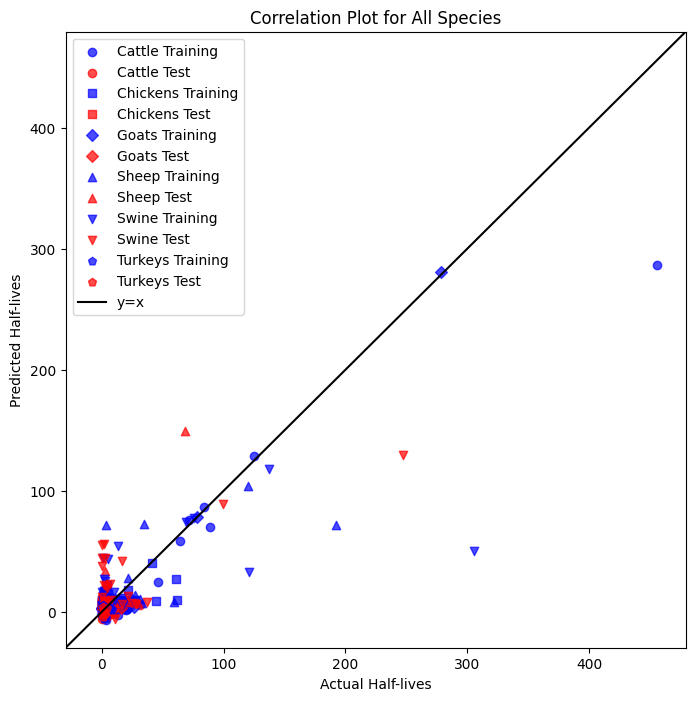

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

animal_list = ['Cattle', 'Chickens', 'Goats', 'Sheep', 'Swine', 'Turkeys']

# Initialize lists to store data for all species
all_y_train = []
all_y_train_preds = []
all_y_test = []
all_y_test_preds = []

# Define plotting markers for each species
markers = ['o', 's', 'D', '^', 'v', 'p']

# Create a scatter plot with a line of r=1 for all species
plt.figure(figsize=(8, 8))  # Make the plot square

# Loop through each species and collect data
for idx, animal in enumerate(animal_list):
    # Filter the data for the current species
    species_data = X_rdkit[X_rdkit[animal] == 1]

    # Check if there are any data points left for plotting
    if not species_data.empty:
        # Collect data for training and test sets
        y_train = species_data['y_train']
        y_train_preds = species_data['y_train_preds_v2']
        y_test = species_data['y_test']
        y_test_preds = species_data['y_test_preds_v2']

        # Store data for all species
        all_y_train.extend(y_train)
        all_y_train_preds.extend(y_train_preds)
        all_y_test.extend(y_test)
        all_y_test_preds.extend(y_test_preds)

        # Plot training set data points for the current species in a darker shade
        plt.scatter(y_train, y_train_preds, color='blue', marker=markers[idx], label=f'{animal} Training', alpha=0.7)

        # Plot test set data points for the current species in a lighter shade
        plt.scatter(y_test, y_test_preds, color='red', marker=markers[idx], label=f'{animal} Test', alpha=0.7)

# Remove NaN or Inf values from the lists
all_y_train = [y for y in all_y_train if np.isfinite(y)]
all_y_train_preds = [y for y in all_y_train_preds if np.isfinite(y)]
all_y_test = [y for y in all_y_test if np.isfinite(y)]
all_y_test_preds = [y for y in all_y_test_preds if np.isfinite(y)]

# Calculate min_val based on the filtered data
combined_data = all_y_train + all_y_train_preds + all_y_test + all_y_test_preds
if combined_data:  # Ensure the list is not empty
    data_range = max(combined_data) - min(combined_data)
    min_val = min(combined_data) - 0.05 * data_range
    max_val = max(combined_data) + 0.05 * data_range
else:
    raise ValueError("No valid data points available for plotting.")

# Plot the y = x line
plt.plot([min_val, max_val], [min_val, max_val], linestyle='-', color='black', label='y=x')

plt.title('Correlation Plot for All Species')
plt.xlabel('Actual Half-lives')
plt.ylabel('Predicted Half-lives')

# Set the limits for both X and Y axes
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)

plt.legend()
plt.show()
